# 🌙 Lunar Landing Suitability – تحليل الداتا + بناء الموديل
**الخطوات:** 1) قراءة الداتا ← 2) شرح الفيتشرز ← 3) Data Quality ← 4) Feature Engineering ← 5) Landing Score & Class ← 6) Modeling ← 7) حفظ الموديل ← 8) دالة التوقع للفرونت إند

In [3]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, json
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

DATA_PATH = "moon_sky_data__1_.csv"   # غيّر المسار لو لازم
df = pd.read_csv("moon_sky_data (1).csv", parse_dates=["time_utc"])
print(df.shape)
df.head()

(2163, 10)


,site_id,site_name,east_longitude_deg,latitude_deg,time_utc,sun_azimuth_deg,sun_elevation_deg,sun_up,earth_visible,source
0,apollo11,Apollo 11 landing site (Mare Tranquillitatis),23.47,0.67,2026-11-13 00:00:00,91.404821,-25.347749,0,1,"NASA JPL Horizons (DE441), observer table, air..."
1,apollo11,Apollo 11 landing site (Mare Tranquillitatis),23.47,0.67,2026-11-13 01:00:00,91.404999,-24.839870,0,1,"NASA JPL Horizons (DE441), observer table, air..."
2,apollo11,Apollo 11 landing site (Mare Tranquillitatis),23.47,0.67,2026-11-13 02:00:00,91.405307,-24.331998,0,1,"NASA JPL Horizons (DE441), observer table, air..."
3,apollo11,Apollo 11 landing site (Mare Tranquillitatis),23.47,0.67,2026-11-13 03:00:00,91.405744,-23.824134,0,1,"NASA JPL Horizons (DE441), observer table, air..."
4,apollo11,Apollo 11 landing site (Mare Tranquillitatis),23.47,0.67,2026-11-13 04:00:00,91.406308,-23.316278,0,1,"NASA JPL Horizons (DE441), observer table, air..."


## 1) شرح الفيتشرز (الأعمدة الموجودة فعليًا في الملف)
| العمود | المعنى |
|---|---|
| `site_id`, `site_name` | معرّف واسم موقع الهبوط (3 مواقع: Apollo 11 / Chang'e 4 / Shackleton rim) |
| `east_longitude_deg` | خط الطول الشرقي بالدرجات |
| `latitude_deg` | خط العرض بالدرجات (القطب الجنوبي ≈ -90) |
| `time_utc` | وقت القياس (كل ساعة، 30 يوم من 2026-11-13) |
| `sun_azimuth_deg` | اتجاه الشمس (0–360°) |
| `sun_elevation_deg` | **ارتفاع الشمس فوق الأفق** (سالب = الشمس تحت الأفق/ليل) |
| `sun_up` | 1 لو الشمس فوق الأفق |
| `earth_visible` | 1 لو الأرض ظاهرة في السماء (مهم للاتصالات المباشرة) |
| `source` | مصدر البيانات (NASA JPL Horizons) – قيمة ثابتة |

⚠️ **أعمدة ذكرتها في طلبك وهي مش موجودة في الملف:** `slope_deg`, `elevation_m`, `illumination_percent`, `earth_visibility_percent`, `Landing Suitability Score`, `Landing Classification`.
- `illumination_percent` و `earth_visibility_percent` هنحسبهم من `sun_up` و `earth_visible` (نسبة الساعات على نافذة 24 ساعة).
- `slope_deg` و `elevation_m` **مفيش طريقة نستنتجهم من الملف** (محتاجين DEM من LOLA مثلًا) – مش هنألفهم.
- الـ Score والـ Class هنبنيهم بقاعدة معلنة (Heuristic) لأن مفيش Label حقيقي في الداتا.

## 2) Data Quality

In [4]:
print("Missing values:\n", df.isna().sum(), "\n")
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated (site,time):", df.duplicated(["site_id","time_utc"]).sum())
print("Constant columns:", [c for c in df.columns if df[c].nunique()==1])

# Range / logic checks
checks = {
 "azimuth within [0,360]": df.sun_azimuth_deg.between(0,360).all(),
 "elevation within [-90,90]": df.sun_elevation_deg.between(-90,90).all(),
 "latitude within [-90,90]": df.latitude_deg.between(-90,90).all(),
 "sun_up consistent with elevation>0": ((df.sun_elevation_deg>0).astype(int)==df.sun_up).all(),
 "sun_up/earth_visible binary": df[["sun_up","earth_visible"]].isin([0,1]).all().all(),
}
print(pd.Series(checks))

# Time regularity per site
gaps = df.sort_values("time_utc").groupby("site_id").time_utc.diff().dropna().value_counts()
print("\nTime step per site:\n", gaps)
print("\nRows per site:\n", df.site_id.value_counts())

Missing values:
 site_id               0
site_name             0
east_longitude_deg    0
latitude_deg          0
time_utc              0
sun_azimuth_deg       0
sun_elevation_deg     0
sun_up                0
earth_visible         0
source                0
dtype: int64 

Duplicated rows: 0
Duplicated (site,time): 0
Constant columns: ['source']
azimuth within [0,360]                True
elevation within [-90,90]             True
latitude within [-90,90]              True
sun_up consistent with elevation>0    True
sun_up/earth_visible binary           True
dtype: bool

Time step per site:
 time_utc
0 days 01:00:00    2160
Name: count, dtype: int64

Rows per site:
 site_id
apollo11          721
change4           721
shackleton_rim    721
Name: count, dtype: int64


In [5]:
# Outliers (IQR) على الأعمدة الرقمية المستمرة
for c in ["sun_azimuth_deg","sun_elevation_deg"]:
    q1,q3 = df[c].quantile([.25,.75]); iqr=q3-q1
    n = ((df[c]<q1-1.5*iqr)|(df[c]>q3+1.5*iqr)).sum()
    print(f"{c}: {n} outliers (IQR) -> قيم فيزيائية طبيعية، مش هنشيلها")

summary = df.groupby("site_id").agg(
    sun_up_pct=("sun_up", lambda s: 100*s.mean()),
    earth_visible_pct=("earth_visible", lambda s: 100*s.mean()),
    elev_min=("sun_elevation_deg","min"), elev_max=("sun_elevation_deg","max"))
summary

sun_azimuth_deg: 0 outliers (IQR) -> قيم فيزيائية طبيعية، مش هنشيلها
sun_elevation_deg: 121 outliers (IQR) -> قيم فيزيائية طبيعية، مش هنشيلها


,sun_up_pct,earth_visible_pct,elev_min,elev_max
site_id,,,,
apollo11,49.375867,100.00000,-89.223007,87.783696
change4,51.595007,0.00000,-43.019556,45.973938
shackleton_rim,100.000000,43.68932,1.207980,1.763130


**نتيجة الـ Data Quality:** الداتا نضيفة (مفيش Nulls ولا Duplicates ولا تناقضات)، لكنها **صغيرة** (2163 صف) و**3 مواقع بس**.
ملاحظات فيزيائية مهمة: Chang'e 4 على الجانب البعيد فـ `earth_visible = 0` طول الوقت (صح علميًا)، وShackleton فيه شمس منخفضة جدًا (أقصى ارتفاع ~1.8°).

## 3) EDA

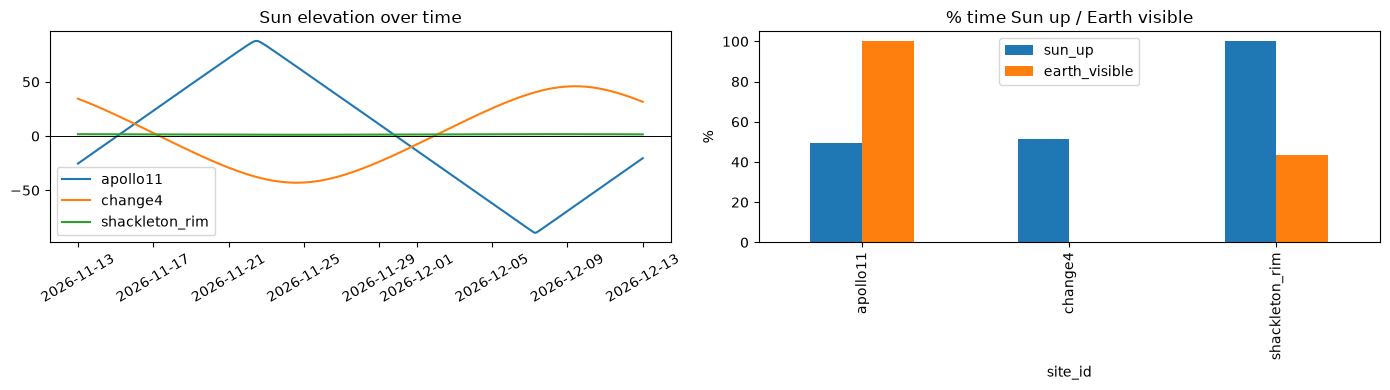

In [6]:
fig, ax = plt.subplots(1,2, figsize=(14,4))
for s,g in df.groupby("site_id"):
    ax[0].plot(g.time_utc, g.sun_elevation_deg, label=s)
ax[0].axhline(0,c="k",lw=.7); ax[0].set_title("Sun elevation over time"); ax[0].legend(); ax[0].tick_params(axis="x",rotation=30)
df.groupby("site_id")[["sun_up","earth_visible"]].mean().mul(100).plot.bar(ax=ax[1])
ax[1].set_title("% time Sun up / Earth visible"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

## 4) Feature Engineering
- `illumination_percent` = نسبة الساعات اللي الشمس فيها فوق الأفق في نافذة 24 ساعة (متمركزة) لكل موقع.
- `earth_visibility_percent` = نفس الفكرة للأرض.
- `hour_of_day` / `day_index` اختيارية للتحليل (مش داخلة في الموديل عشان ما نعتمدش على الوقت).

In [7]:
df = df.sort_values(["site_id","time_utc"]).reset_index(drop=True)
W = 24
g = df.groupby("site_id")
df["illumination_percent"]      = g["sun_up"].transform(lambda s: s.rolling(W, center=True, min_periods=1).mean()*100)
df["earth_visibility_percent"]  = g["earth_visible"].transform(lambda s: s.rolling(W, center=True, min_periods=1).mean()*100)
df[["site_id","time_utc","sun_elevation_deg","illumination_percent","earth_visibility_percent"]].describe()

,time_utc,sun_elevation_deg,illumination_percent,earth_visibility_percent
count,2163,2163.000000,2163.000000,2163.000000
mean,2026-11-28 00:00:00,0.948745,66.990291,47.896440
min,2026-11-13 00:00:00,-89.223007,0.000000,0.000000
25%,2026-11-20 12:00:00,-17.933840,0.000000,0.000000
50%,2026-11-28 00:00:00,1.507594,100.000000,0.000000
75%,2026-12-05 12:00:00,19.299495,100.000000,100.000000
max,2026-12-13 00:00:00,87.783696,100.000000,100.000000
std,NaN,34.633222,46.243656,49.596278


## 5) Landing Suitability Score (0–100) + Classification
بما إن مفيش Label حقيقي، بنعرّف **قاعدة هندسية معلنة** (تقدر تعدّل الأوزان):

- **Sun elevation (40%)**: الشمس تحت الأفق = 0 (ظلام). من 0→5° تصاعدي. **5–30° = مثالي** (ظلال طويلة تساعد كشف العوائق + طاقة كويسة). فوق 30° بتقل تدريجيًا لحد 0.5 عند 60°+ (تسخين وظلال ضعيفة).
- **Illumination % (30%)**: نسبة الإضاءة (طاقة شمسية/حرارة).
- **Earth visibility % (30%)**: الاتصال المباشر بالأرض.

التصنيف: `Excellent ≥ 75` · `Good 55–75` · `Moderate 35–55` · `Poor < 35`.

In [8]:
def elevation_factor(e):
    e = np.asarray(e, dtype=float)
    return np.select(
        [e<=0, e<5, e<=30, e<60],
        [0.0,  e/5, 1.0,  1.0-0.5*(e-30)/30],
        default=0.5)

WEIGHTS = {"elev":0.40, "illum":0.30, "earth":0.30}
BINS   = [-np.inf, 35, 55, 75, np.inf]
LABELS = ["Poor","Moderate","Good","Excellent"]

def landing_score(sun_elevation_deg, illumination_percent, earth_visibility_percent):
    return 100*(WEIGHTS["elev"]*elevation_factor(sun_elevation_deg)
              + WEIGHTS["illum"]*np.asarray(illumination_percent)/100
              + WEIGHTS["earth"]*np.asarray(earth_visibility_percent)/100)

def classify(score):
    return pd.cut(pd.Series(np.atleast_1d(score)), BINS, labels=LABELS).astype(str).values

df["landing_score"] = landing_score(df.sun_elevation_deg, df.illumination_percent, df.earth_visibility_percent)
df["landing_class"] = classify(df.landing_score)
print(df.landing_class.value_counts())
print(pd.crosstab(df.site_id, df.landing_class))
df.groupby("site_id").landing_score.describe()

landing_class
Poor         709
Good         678
Moderate     432
Excellent    344
Name: count, dtype: int64
landing_class   Excellent  Good  Moderate  Poor
site_id                                        
apollo11              344     8        19   350
change4                 0   352        10   359
shackleton_rim          0   318       403     0


,count,mean,std,min,25%,50%,75%,max
site_id,,,,,,,,
apollo11,721.0,59.061184,29.857025,30.000000,30.00000,42.500000,86.874543,100.000000
change4,721.0,33.524385,32.628529,0.000000,0.00000,36.773208,67.754746,70.000000
shackleton_rim,721.0,55.070571,13.127119,41.895256,43.32124,44.088552,69.955608,71.404776


## 6) Modeling
**الفيتشرز اللي بتدخل الموديل:**
`sun_elevation_deg`, `sun_azimuth_deg`, `latitude_deg`, `east_longitude_deg`, `illumination_percent`, `earth_visibility_percent`, `earth_visible`.

التقسيم **زمني** (أول 70% من الوقت تدريب / آخر 30% اختبار) بدل عشوائي، عشان القياسات المتتالية مترابطة جدًا.

In [9]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

FEATURES = ["sun_elevation_deg","sun_azimuth_deg","latitude_deg","east_longitude_deg",
            "illumination_percent","earth_visibility_percent","earth_visible"]

cut = df.time_utc.quantile(0.7)
train, test = df[df.time_utc<=cut], df[df.time_utc>cut]
Xtr, Xte = train[FEATURES], test[FEATURES]
print("train/test:", len(train), len(test))

reg = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(Xtr, train.landing_score)
clf = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1).fit(Xtr, train.landing_class)

p = reg.predict(Xte); c = clf.predict(Xte)
print(f"Regression  MAE={mean_absolute_error(test.landing_score,p):.2f}  R2={r2_score(test.landing_score,p):.3f}")
print(f"Classifier  Acc={accuracy_score(test.landing_class,c):.3f}  macroF1={f1_score(test.landing_class,c,average='macro'):.3f}")
print(classification_report(test.landing_class, c, zero_division=0))

train/test: 1515 648
Regression  MAE=1.68  R2=0.945
Classifier  Acc=1.000  macroF1=1.000
              precision    recall  f1-score   support

        Good       1.00      1.00      1.00       216
    Moderate       1.00      1.00      1.00       216
        Poor       1.00      1.00      1.00       216

    accuracy                           1.00       648
   macro avg       1.00      1.00      1.00       648
weighted avg       1.00      1.00      1.00       648



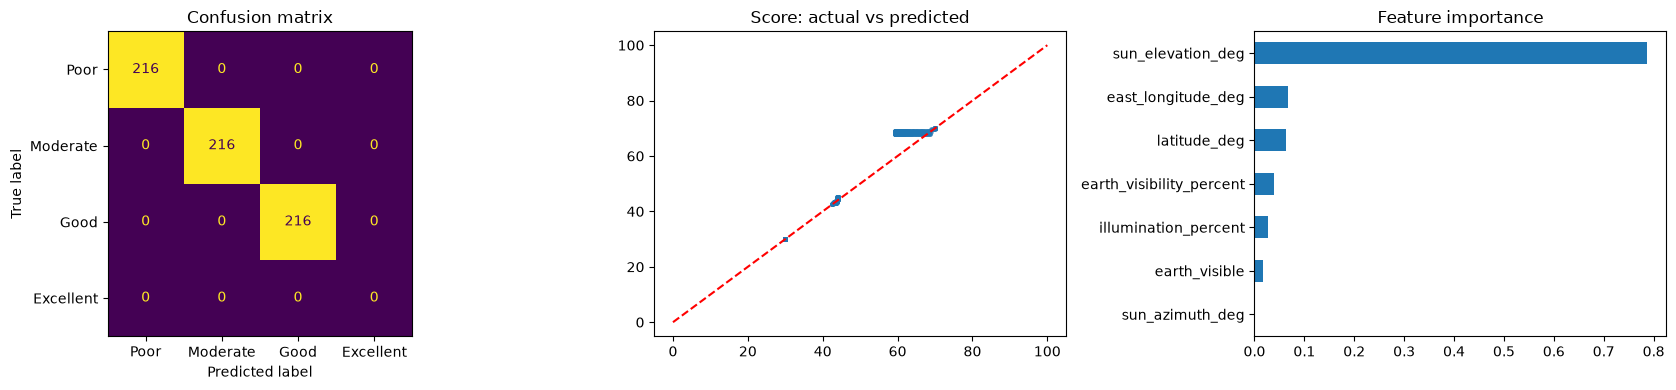

In [10]:
fig, ax = plt.subplots(1,3, figsize=(17,4))
ConfusionMatrixDisplay.from_predictions(test.landing_class, c, labels=LABELS, ax=ax[0], colorbar=False); ax[0].set_title("Confusion matrix")
ax[1].scatter(test.landing_score, p, s=6, alpha=.5); ax[1].plot([0,100],[0,100],"r--"); ax[1].set_title("Score: actual vs predicted")
imp = pd.Series(reg.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(ax=ax[2]); ax[2].set_title("Feature importance")
plt.tight_layout(); plt.show()

### ⚠️ قراءة النتائج بأمانة
الـ Label مبني من نفس الفيتشرز (عن طريق القاعدة)، فالدقة العالية معناها إن الموديل **اتعلّم القاعدة**، مش إنه اكتشف حقيقة جديدة عن القمر. الموديل ده يُستخدم كـ **Surrogate/Prototype** لحد ما يتوفر:
1. `slope_deg` و `elevation_m` (من LOLA DEM) لكل موقع.
2. Labels حقيقية (خبراء / مهام سابقة / معايير ناسا) وعدد مواقع أكبر بكتير من 3.

## 7) حفظ الموديل

In [11]:
final_reg = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(df[FEATURES], df.landing_score)
final_clf = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1).fit(df[FEATURES], df.landing_class)

bundle = {"regressor": final_reg, "classifier": final_clf, "features": FEATURES,
          "bins": BINS[1:-1], "labels": LABELS, "weights": WEIGHTS}
joblib.dump(bundle, "landing_model.joblib")
json.dump({"features":FEATURES,"labels":LABELS,"thresholds":BINS[1:-1]}, open("model_meta.json","w"), indent=2)
print("saved: landing_model.joblib , model_meta.json")

saved: landing_model.joblib , model_meta.json


## 8) دالة التوقع (اللي الفرونت إند هيكلمها)

In [12]:
def predict_site(sun_elevation_deg, illumination_percent, earth_visibility_percent,
                 sun_azimuth_deg=180.0, latitude_deg=0.0, east_longitude_deg=0.0, earth_visible=None,
                 slope_deg=None, elevation_m=None):
    b = joblib.load("landing_model.joblib")
    if earth_visible is None: earth_visible = int(earth_visibility_percent > 50)
    x = pd.DataFrame([[sun_elevation_deg, sun_azimuth_deg, latitude_deg, east_longitude_deg,
                       illumination_percent, earth_visibility_percent, earth_visible]], columns=b["features"])
    score = float(b["regressor"].predict(x)[0])
    cls = str(b["classifier"].predict(x)[0])
    return {"landing_score": round(score,1), "landing_class": cls,
            "suitable": cls in ("Excellent","Good"),
            "note": "slope_deg/elevation_m غير مستخدمين في الموديل الحالي"}

print(predict_site(15, 85, 90))   # شمس 15°، إضاءة 85%، أرض 90%
print(predict_site(-10, 0, 100))  # ليل
print(predict_site(1.2, 55, 40, latitude_deg=-89.68, east_longitude_deg=194))

{'landing_score': 95.3, 'landing_class': 'Excellent', 'suitable': True, 'note': 'slope_deg/elevation_m غير مستخدمين في الموديل الحالي'}
{'landing_score': 30.0, 'landing_class': 'Poor', 'suitable': False, 'note': 'slope_deg/elevation_m غير مستخدمين في الموديل الحالي'}
{'landing_score': 57.9, 'landing_class': 'Moderate', 'suitable': False, 'note': 'slope_deg/elevation_m غير مستخدمين في الموديل الحالي'}
